# 04 · Detección genérica de anomalías (Isolation Forest y LOF)

> Datos **simulados**, fraude **plantado** sobre líneas y empresas ficticias. Ver `00c_simulacion_secciones.ipynb`.
> Con datos reales esto produciría "anomalías a revisar", nunca prueba de fraude.

Los métodos anteriores incorporan una idea sobre el fraude (la tarifa salta, la cobranza no es plausible para el recorrido). Este **no incorpora ninguna**: le damos a un algoritmo genérico los rasgos de cada línea-mes y le pedimos que marque lo "raro".
Sirve para preguntar: ¿cuánto de lo que detectan los métodos específicos se logra con un detector de uso general?

## Las dos herramientas, sin fórmulas
- **Isolation Forest:** arma muchos árboles que cortan los datos al azar. Un punto raro queda aislado en pocos cortes; uno típico necesita muchos. Puntaje = qué tan fácil es aislarlo. Mide rareza **global**.
- **LOF (Local Outlier Factor):** compara la densidad de vecinos de un punto con la de sus vecinos. Un punto en una zona vacía rodeada de zonas densas es anómalo. Mide rareza **local**.

## Protocolo
1. Entrenamos con el pasado (que asumimos limpio) y puntuamos períodos posteriores.
2. Puntaje de una línea = promedio de sus últimos 6 meses.
3. Umbral = percentil 95 de un **placebo**: el mismo cálculo en un período sin fraude.
4. Probamos dos conjuntos de rasgos: solo **niveles** (reparto por secciones, tarifa relativa al grupo, largo, tamaño) y **niveles + cambios** (cuánto se apartó cada línea de su propio promedio de hace 10-21 meses).

In [1]:
import sys; sys.path.append('../src')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from anomalias import rasgos, Detector, puntaje_linea, NIVELES, CAMBIOS
sim = pd.read_parquet('../data/processed/sim_secciones.parquet')
d = rasgos(sim)    # usa solo columnas observables; nada de verdad_*
print('Rasgos de nivel:', NIVELES); print('Rasgos de cambio:', CAMBIOS)
print(f'Filas: {len(d):,} | filas con rasgos de cambio disponibles: {d[CAMBIOS[0]].notna().mean():.0%}')

Rasgos de nivel: ['log_tm_rel', 'altas', 'pct_sec_max', 'log_largo', 'log_viajes', 'log_dist_centro', 's1', 's2', 's3', 's4', 's5']
Rasgos de cambio: ['d_log_tm_rel', 'd_altas']
Filas: 26,642 | filas con rasgos de cambio disponibles: 79%


## 1. Un primer intento… con una trampa
Entrenamos hasta diciembre de 2024, calibramos el umbral con el semestre jul-dic 2025 y evaluamos abril-octubre 2026. Parece razonable. Veamos los resultados.

In [2]:
def evaluar(cols, modelo, train_eval, train_null, as_of_eval, as_of_null, ventana=6):
    A, B = Detector(modelo, cols, train_eval).fit(d), Detector(modelo, cols, train_null).fit(d)
    r, n = puntaje_linea(d, A.puntuar(d), as_of_eval, ventana), puntaje_linea(d, B.puntuar(d), as_of_null, ventana)
    h = pd.Timestamp(as_of_eval)
    verdad = d[(d.mes <= h) & (d.mes > h - pd.DateOffset(months=ventana))].groupby('linea_id').verdad_fraude_activo.any()
    df = pd.DataFrame({'s': r}).join(verdad.rename('fraude')).dropna()
    thr = n.quantile(.95); f = df.s > thr
    tp, fp, fn = int((f & df.fraude).sum()), int((f & ~df.fraude).sum()), int((~f & df.fraude).sum())
    return {'auc': roc_auc_score(df.fraude, df.s), 'umbral': round(thr, 2), 'TP': tp, 'FP': fp, 'FN': fn,
            'tasa_FP': fp / (~df.fraude).sum(), 'top25': int(df.sort_values('s', ascending=False).head(25).fraude.sum()), 'df': df, 'det': A}

conj = {'niveles': NIVELES, 'niveles+cambios': NIVELES + CAMBIOS}
filas = []
for cn, cols in conj.items():
    for mod in ('iforest', 'lof'):
        e = evaluar(cols, mod, '2024-12-01', '2024-12-01', '2026-10-01', '2025-12-01')
        filas.append({'rasgos': cn, 'modelo': mod, 'AUC': round(e['auc'], 3), 'TP': e['TP'], 'FP': e['FP'], 'FN': e['FN'], '% falsas alarmas': f"{e['tasa_FP']:.0%}"})
pd.DataFrame(filas)

,rasgos,modelo,AUC,TP,FP,FN,% falsas alarmas
0,niveles,iforest,0.731,0,16,25,6%
1,niveles,lof,0.968,23,19,2,7%
2,niveles+cambios,iforest,0.921,6,17,19,6%
3,niveles+cambios,lof,1.000,25,67,0,25%


**Observación:** con un umbral pensado para marcar al 5 % de las líneas sin fraude, LOF con rasgos de nivel marca ~7 % y con rasgos de cambio ~25 %. Es decir, **más falsas alarmas de las buscadas**, sobre todo con los rasgos de cambio.
Al mirar el puntaje mes a mes de las líneas **sin fraude** se ve una **deriva**: dentro del período de entrenamiento el percentil 95 es ~1,1, apenas termina salta a ~1,5 (2025) y en 2026 sube a ~1,8. Un modelo puntúa más duro lo que no vio, y más cuanto más se aleja en el tiempo.
Eso sugirió una corrección: que el placebo esté a la *misma distancia* del entrenamiento que el período evaluado. La probamos:

## 2. Protocolo emparejado
Evaluamos los 6 meses siguientes al fin del entrenamiento (entrenado hasta dic-2025, evaluado ene-jun 2026). El placebo replica exactamente esa distancia: modelo entrenado hasta jun-2025, puntuando jul-dic 2025.

In [3]:
res, filas = {}, []
for cn, cols in conj.items():
    for mod in ('iforest', 'lof'):
        e = evaluar(cols, mod, '2025-12-01', '2025-06-01', '2026-06-01', '2025-12-01'); res[(cn, mod)] = e
        filas.append({'rasgos': cn, 'modelo': mod, 'AUC': round(e['auc'], 3), 'umbral': e['umbral'], 'TP': e['TP'], 'FP': e['FP'], 'FN': e['FN'],
                      '% falsas alarmas': f"{e['tasa_FP']:.0%}", 'aciertos en top 25': e['top25']})
tabla = pd.DataFrame(filas); tabla

,rasgos,modelo,AUC,umbral,TP,FP,FN,% falsas alarmas,aciertos en top 25
0,niveles,iforest,0.729,0.57,1,18,23,6%,3
1,niveles,lof,0.961,1.54,22,23,2,8%,20
2,niveles+cambios,iforest,0.910,0.55,7,18,12,7%,7
3,niveles+cambios,lof,1.000,1.42,19,58,0,23%,19


**Cómo leerlo:**
- **Isolation Forest** queda bien calibrado (≈ 6 % de falsas alarmas, cerca del 5 % buscado) pero **detecta muy poco**: marca casi nada de lo que importa. Rareza *global* no es lo mismo que cambio: una línea que sube su tarifa unos puntos sigue estando dentro de la nube de líneas normales.
- **LOF** **ordena casi perfecto** (AUC ≈ 1 con rasgos de cambio) pero su umbral no se transfiere bien: ~8 % de falsas alarmas con niveles y ~23 % con rasgos de cambio.
  **Emparejar la distancia no resolvió el problema** (7 % → 8 % con niveles, 25 % → 23 % con cambios, casi igual que antes). La deriva existe, pero no explica por sí sola el exceso de falsas alarmas de LOF; **la causa queda sin identificar**. Una hipótesis que **no verificamos** para los rasgos de cambio es que la tarifa relativa al grupo se contamina en 2026 (el fraude sube la mediana del grupo) pero no en el placebo. (Para los rasgos de nivel sí la probamos en una versión anterior y no se sostuvo.)

## 3. ¿Por qué LOF ordena tan bien, si no sabe nada del fraude?
Cada línea aparece unas 60 veces en el entrenamiento, y sus puntos quedan **juntos** en una zona muy chica del espacio de rasgos. Cuando una línea cambia su reparto de secciones, sale de su propia nube y cae en una zona vacía.
Una explicación probable (que no aislamos con un experimento) es que LOF **recuerda a cada línea** y detecta que se aleja de su pasado: sería un método de quiebre disfrazado, comparable al método 01, aunque no se lo hayamos pedido.

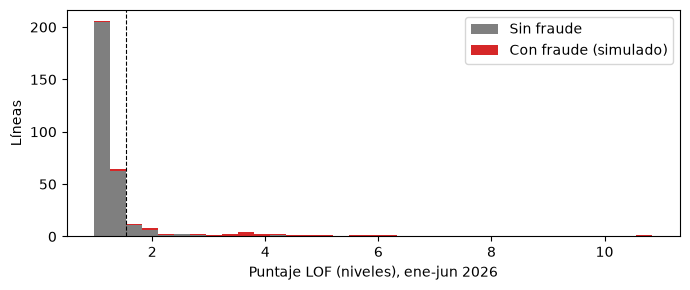

In [4]:
e = res[('niveles', 'lof')]; df = e['df']
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist([df[~df.fraude].s, df[df.fraude].s], bins=35, stacked=True, color=['tab:gray', 'tab:red'], label=['Sin fraude', 'Con fraude (simulado)'])
ax.axvline(e['umbral'], ls='--', color='k', lw=.8); ax.set_xlabel('Puntaje LOF (niveles), ene-jun 2026'); ax.set_ylabel('Líneas'); ax.legend(); plt.tight_layout()
plt.savefig('../outputs/figures/m04_distribucion_lof.png', dpi=150); plt.show()

## 4. ¿Por qué marcó a cada línea? (explicabilidad)
Un ranking sin explicación sirve poco para revisar. Para las 5 líneas con mayor puntaje, vemos cuáles rasgos se apartan más de lo normal (en desvíos respecto del entrenamiento). Es una herramienta de lectura, no una prueba.

In [5]:
cols = NIVELES + CAMBIOS
A = Detector('lof', cols, '2025-12-01').fit(d)
top = res[('niveles+cambios', 'lof')]['df'].sort_values('s', ascending=False).head(5).index
w = d[(d.mes > '2025-12-01') & (d.mes <= '2026-06-01') & d.linea_id.isin(top)].dropna(subset=cols)
Z = pd.DataFrame(A.esc.transform(w[cols]), columns=cols, index=w.index).assign(linea_id=w.linea_id).groupby('linea_id').mean()
Z.loc[top].round(1)[['d_log_tm_rel', 'd_altas', 'altas', 's1', 's2', 's3', 's4', 'log_tm_rel']]

,d_log_tm_rel,d_altas,altas,s1,s2,s3,s4,log_tm_rel
linea_id,,,,,,,,
L369,17.0,22.9,-0.9,1.9,-2.3,-1.3,-0.5,1.6
L141,14.7,20.5,-0.4,0.9,-1.2,-0.4,-0.3,1.1
L236,10.9,18.9,-0.3,0.6,-0.8,-0.2,-0.3,0.5
L361,12.7,17.9,-0.0,0.2,-0.6,0.3,-0.2,1.9
L027,10.4,18.4,-0.1,0.2,-0.3,0.1,-0.2,1.0


Lo que más se aparta son los rasgos de **cambio** (`d_altas`, `d_log_tm_rel`, entre 10 y 20 desvíos), mientras que los **niveles** (`altas`, `s1`…`s4`) quedan cerca de lo normal. Esto también explica por qué Isolation Forest con solo niveles no ve nada: el fraude mueve a la línea poco *respecto de la nube de todas*, pero mucho *respecto de sí misma*. El detector no "sabe" del fraude, pero lo que lo delata coincide con su lógica.

## 5. Guardar y comparar

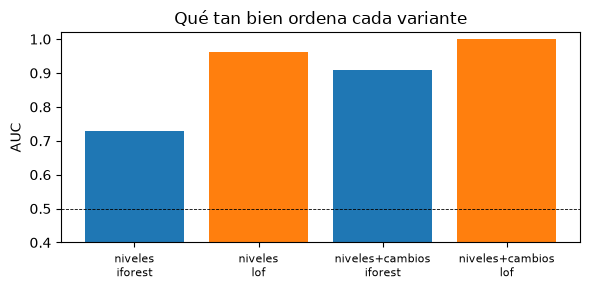

In [6]:
out = []
for (cn, mod), e in res.items():
    out.append(e['df'].reset_index().assign(rasgos=cn, modelo=mod))
pd.concat(out).to_parquet('../data/processed/res_m04_anomalias.parquet')
fig, ax = plt.subplots(figsize=(6, 3))
t = tabla.assign(variante=tabla.rasgos + '\n' + tabla.modelo)
ax.bar(t.variante, t.AUC, color=['tab:blue', 'tab:orange', 'tab:blue', 'tab:orange']); ax.axhline(.5, color='k', lw=.6, ls='--'); ax.set_ylim(.4, 1.02)
ax.set_ylabel('AUC'); ax.set_title('Qué tan bien ordena cada variante'); plt.xticks(fontsize=8); plt.tight_layout()
plt.savefig('../outputs/figures/m04_auc_variantes.png', dpi=150); plt.show()

## Conclusiones y limitaciones
- **Un detector genérico puede ordenar muy bien (LOF) pero no es confiable para decidir.** Ordena casi perfecto; el umbral no se sostiene.
- **La calibración del umbral de LOF es frágil y no pudimos resolverla:** hay deriva en el puntaje, igualar la distancia del placebo no alcanzó, y los rasgos "relativos al grupo" pueden contaminarse cuando el fraude afecta a varias líneas.
- **Lo que parece detección de rarezas probablemente sea, en parte, memoria de cada línea** (LOF; hipótesis, no aislada). Cuando un detector genérico funciona, conviene preguntarse qué está haciendo realmente.
- **Isolation Forest** queda bien calibrado pero casi no sirve acá: el fraude de 20 % mueve a las líneas dentro de la nube de lo normal.
- **Supuestos de la simulación:** la simulación no tiene deriva real (cambios de demanda, estacionalidad fuerte, obras) que este tipo de detectores sí sufren con datos reales; las falsas alarmas reales serían mayores.
- **Siguiente (método 05, opcional):** inferir el descenso encadenando validaciones, el método más fuerte porque mide directamente el trayecto real y no depende de series agregadas. Requiere microdatos simulados de validaciones.